In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
import pickle
from hypergraphx import Hypergraph

from src.utils import hyperedge_homogeneity_list, hypergraph_disjointness

In [2]:
# All HyperLap datasets: hyperedge homogeneity + basic hypergraph stats
DATASET_DIR = Path("data/real").resolve()

homogeneity_by_dataset: dict = {}

for txt_path in sorted(DATASET_DIR.glob("*_graph.txt")):
    key = txt_path.stem.replace("_graph", "")
    
    edge_list = []
    with open(txt_path, "r") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            tokens = line.replace(",", " ").split()
            edge_list.append([int(x) for x in tokens])
    
    H = Hypergraph(edge_list)
    
    n_nodes = len(H.get_nodes())
    n_edges = len(H.get_edges())

    deg_dist = H.degree_distribution()
    mean_node_degree = float(sum(deg * cnt for deg, cnt in deg_dist.items()) / n_nodes)

    edge_sizes = H.get_sizes()
    mean_hyperedge_size = float(np.mean(edge_sizes)) if len(edge_sizes) > 0 else float("nan")

    hom_list = hyperedge_homogeneity_list(H)
    disjointness = hypergraph_disjointness(H)
    
    homogeneity_by_dataset[key] = {
        "H": H,
        "path": str(txt_path),
        "n_nodes": len(H.get_nodes()),
        "n_edges": len(H.get_edges()),
        "mean_node_degree": mean_node_degree,
        "mean_hyperedge_size": mean_hyperedge_size,
        "min_hyperedge_size": min(edge_sizes),
        "max_hyperedge_size": max(edge_sizes),
        "hyperedge_homogeneity": hom_list,
        "mean_homogeneity": np.mean(hom_list),
        "median_homogeneity": np.median(hom_list),
        "std_homogeneity": np.std(hom_list),
        "disjointness": disjointness
    }


contact-high:
    n_edges=7818, n_nodes=327
    mean_hyperedge_size=2.33, mean_node_degree=55.63
    mean_homogeneity: 3.48, disjointness: 0.074
contact-primary:
    n_edges=12704, n_nodes=242
    mean_hyperedge_size=2.42, mean_node_degree=126.98
    mean_homogeneity: 5.03, disjointness: 0.08
email-Enron-full:
    n_edges=1459, n_nodes=143
    mean_hyperedge_size=3.13, mean_node_degree=31.94
    mean_homogeneity: 9.23, disjointness: 1.627
email-Eu-full:
    n_edges=24520, n_nodes=986
    mean_hyperedge_size=3.62, mean_node_degree=90.04
    mean_homogeneity: 25.81, disjointness: 0.408
Saved: results/images/real_homogeneity.png


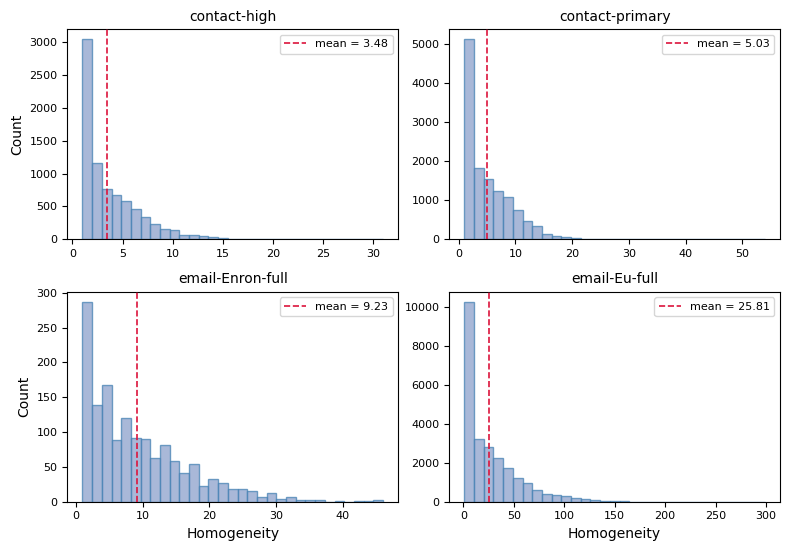

In [12]:
colors = plt.get_cmap("Set2").colors

names = list(homogeneity_by_dataset.keys())
n = len(names)
ncols = 2
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(8, 6), squeeze=False)
axes_flat = axes.ravel()

for i, name in enumerate(names):
    ax = axes_flat[i]
    hom = homogeneity_by_dataset[name]["hyperedge_homogeneity"]
    # ax.hist(hom, bins=40, edgecolor="steelblue", alpha=0.75, color="lightsteelblue")
    ax.hist(hom, bins=31, edgecolor="steelblue", alpha=0.75, color=colors[2])
    mu = float(homogeneity_by_dataset[name]["mean_homogeneity"])
    ax.axvline(mu, color="crimson", linestyle="--", linewidth=1.2, zorder=3, label=f"mean = {mu:.2f}")
    ax.set_title(name, fontsize=10)
    ax.legend(fontsize=8, loc="best")
    if i >= ncols:
        ax.set_xlabel("Homogeneity", fontsize=10)
    else:
        ax.set_xlabel("")
    if i % ncols == 0:
        ax.set_ylabel("Count", fontsize=10)
    else:
        ax.set_ylabel("")
    ax.tick_params(labelsize=8)
    print(f"{name}:")
    print(f"    n_edges={homogeneity_by_dataset[name]['n_edges']}, n_nodes={homogeneity_by_dataset[name]['n_nodes']}")
    print(f"    mean_hyperedge_size={round(homogeneity_by_dataset[name]['mean_hyperedge_size'], 2)}, mean_node_degree={round(homogeneity_by_dataset[name]['mean_node_degree'], 2)}")
    print(f"    mean_homogeneity: {round(homogeneity_by_dataset[name]['mean_homogeneity'], 2)}, disjointness: {round(homogeneity_by_dataset[name]['disjointness']*100, 3)}")

for j in range(n, len(axes_flat)):
    axes_flat[j].set_visible(False)


fig.tight_layout(rect=[0, 0, 1, 0.935])
fig.subplots_adjust(hspace=0.25, wspace=0.155)

out_path = "results/images/real_homogeneity.png"
fig.savefig(out_path, dpi=300)
print(f"Saved: {out_path}")

plt.show()